# ARTI 감정 분석 AI 검증 노트북

ARTI는 작품의 **그림(이미지)**과 **미술관 해설(텍스트)**을 오픈소스 AI 모델로 분석해 **감정 6가지 점수**(평온·기쁨·슬픔·긴장·경외·그리움)를 만들고,
이 점수를 사용자 취향과 비교해 작품을 추천합니다. 이 노트북은 그 AI가 **얼마나 맞는지, 어디가 약한지**를 그래프로 확인합니다.

| 구분 | 모델 | 방식 |
|---|---|---|
| 이미지 | `openai/clip-vit-base-patch32` (CLIP) | 그림과 "a calm and peaceful painting" 같은 감정 문장의 유사도 |
| 텍스트 | `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli` (다국어 NLI) | 해설이 "이 글이 묘사하는 작품의 분위기는 평온함이다"를 뒷받침하는 정도 |

> **중요한 전제:** 두 모델 모두 **파인튜닝(추가 학습)을 하지 않은 사전학습 모델**을 그대로 쓰는 **제로샷** 방식입니다.
> 우리가 한 일은 ① 감정 문장(프롬프트) 설계, ② 라벨 편향 보정, ③ 모델 비교·선택입니다.

**검증 순서**
1. 평가 데이터 확인 → 2. 텍스트 분석 실행 → 3. 라벨 편향 → 4. 정확도(무작위 기준·보정 전후·교차검증) → 5. 혼동 행렬
→ 6. 텍스트 모델 비교 → 7. 이미지(CLIP) 갤러리 → 8. 이미지+텍스트 결합 → 9. 추천과의 연결 → 10. 팀 라벨 일치도 → 11. 결론

**실행 방법**
- **VS Code / Jupyter (로컬):** `ai-service/.venv`를 커널로 선택하고 `pip install matplotlib pandas ipykernel` 후 위에서부터 실행
- **Google Colab:** `ai-service` 폴더를 zip으로 압축해 왼쪽 「파일」 탭에 `ai-service.zip`으로 올린 뒤 위에서부터 실행 (모델 약 1.7GB 자동 다운로드)

## 0. 실행 환경 준비

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab: 업로드한 ai-service.zip 풀기 + 한글 폰트 설치 (torch·transformers는 Colab에 기본 설치되어 있음)
    if not os.path.exists("ai-service") and os.path.exists("ai-service.zip"):
        subprocess.run(["unzip", "-q", "ai-service.zip"], check=True)
    os.chdir("ai-service")
    subprocess.run('pip -q install "transformers>=4.46,<5" sentencepiece protobuf', shell=True)
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
elif os.path.basename(os.getcwd()) == "evaluation":
    os.chdir("..")  # 로컬: evaluation 폴더에서 열었으면 ai-service 폴더로 이동

sys.path.insert(0, os.getcwd())
print("작업 폴더:", os.getcwd())

작업 폴더: /home/user/arti/ai-service


In [2]:
import json, math, time, re, io, urllib.request, logging, warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

from app.emotions import EMOTIONS, EMOTION_KEYS
from app.analyzer import HuggingFaceScorer, apply_prior, combine, load_calibration, normalize_sum, scale_to_max
from app import config

# 실행과 상관없는 경고 메시지 숨기기
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)


def set_korean_font():
    # 한글이 깨지지 않도록 설치된 한글 폰트를 찾아 사용 (Windows: 맑은 고딕, Mac: AppleGothic, Colab: 나눔고딕)
    for path in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf"]:
        if os.path.exists(path):
            font_manager.fontManager.addfont(path)
    names = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "WenQuanYi Zen Hei"]:
        if name in names:
            plt.rcParams["font.family"] = name
            break
    plt.rcParams["axes.unicode_minus"] = False


set_korean_font()
pd.set_option("display.max_colwidth", 60)

KO = {e["key"]: e["ko"] for e in EMOTIONS}
KO_LIST = [KO[k] for k in EMOTION_KEYS]
FIG_DIR = Path("evaluation/results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name, dpi=150):
    # 발표 자료·README에 쓸 수 있게 그래프를 PNG로도 저장
    fig.savefig(FIG_DIR / f"{name}.png", dpi=dpi, bbox_inches="tight")


def heatmap(ax, values, rows, cols, title, fmt="{:.2f}", cmap="Reds", vmax=None):
    im = ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else max(1e-9, np.nanmax(values)), aspect="auto")
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(rows)), rows)
    ax.set_title(title)
    top = np.nanmax(values) if vmax is None else vmax
    for i in range(len(rows)):
        for j in range(len(cols)):
            v = values[i][j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if v > top * 0.6 else "black")
    return im


print("한글 폰트:", plt.rcParams["font.family"])

한글 폰트: ['WenQuanYi Zen Hei']


## 1. 평가 데이터

`evaluation/eval_set.json`: 작품 해설 + 작품마다 **대표 감정 "정답" 1~2개**.

> ⚠️ **현재 정답은 1명(개발자)이 판단한 예시 라벨이고, 작품도 목업 11점뿐입니다.**
> 그래서 이 노트북의 정확도는 "대략적인 경향"으로만 봐야 합니다. 팀원 라벨을 모으는 방법은 10장에 있습니다.

In [3]:
data = json.loads(Path("evaluation/eval_set.json").read_text(encoding="utf-8"))
items = data["items"]
pd.DataFrame(
    [{"id": it["id"], "작품": it["title"], "작가": it["artist"],
      "정답 감정": ", ".join(KO[e] for e in it["expected"]), "해설 글자 수": len(it["description"])} for it in items]
)

,id,작품,작가,정답 감정,해설 글자 수
0,aw-01,별이 빛나는 밤,빈센트 반 고흐,"경외, 긴장",163
1,aw-02,수련,클로드 모네,평온,148
2,aw-03,붉은 방 (붉은색의 조화),앙리 마티스,기쁨,147
3,aw-04,해바라기,빈센트 반 고흐,기쁨,113
4,aw-05,"인상, 해돋이",클로드 모네,"평온, 그리움",125
5,aw-06,구성 VIII,바실리 칸딘스키,"기쁨, 긴장",107
6,aw-07,절규,에드바르 뭉크,"긴장, 슬픔",138
7,aw-08,그랑드자트섬의 일요일 오후,조르주 쇠라,"평온, 기쁨",103
8,aw-09,키스,구스타프 클림트,기쁨,106
9,aw-10,진주 귀고리를 한 소녀,요하네스 페르메이르,"평온, 그리움",117


## 2. 텍스트 분석 실행 (서비스와 같은 모델·문장)

서비스(`app/analyzer.py`)의 `HuggingFaceScorer.text_scores`를 그대로 호출합니다. 감정마다 0~1의 독립 확률(다중 라벨)이 나옵니다.
처음 실행하면 모델을 내려받느라 몇 분 걸리고, 이후에는 작품당 수 초입니다(CPU 기준).

모델 로딩 6.9초


작품 11점 분석 · 작품당 0.9초


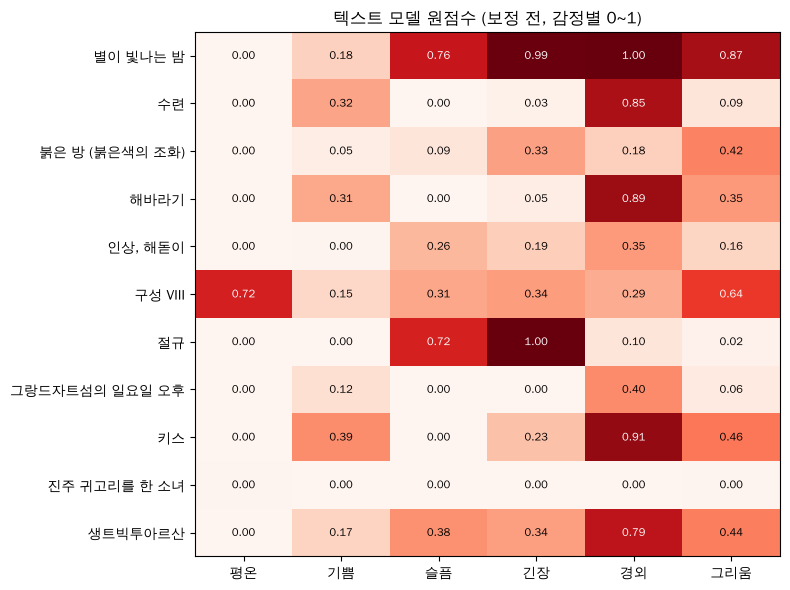

In [4]:
scorer = HuggingFaceScorer()
t0 = time.time()
scorer.load()
print(f"모델 로딩 {time.time() - t0:.1f}초")

raw = {}
t0 = time.time()
for it in items:
    raw[it["id"]] = scorer.text_scores(it["description"])
sec_per_item = (time.time() - t0) / len(items)
print(f"작품 {len(items)}점 분석 · 작품당 {sec_per_item:.1f}초")

titles = [it["title"] for it in items]
raw_mat = np.array([[raw[it["id"]][k] for k in EMOTION_KEYS] for it in items])
fig, ax = plt.subplots(figsize=(8, 6))
heatmap(ax, raw_mat, titles, KO_LIST, "텍스트 모델 원점수 (보정 전, 감정별 0~1)", vmax=1)
fig.tight_layout(); save(fig, "01_text_raw_heatmap"); plt.show()

## 3. 라벨 편향 — 모델이 "어떤 글에나" 높게 주는 감정

제로샷 분류 모델은 내용과 상관없이 특정 라벨에 점수를 많이 주는 버릇(라벨 편향)이 있습니다.
모든 작품에 대한 **감정별 평균 점수**를 보면 바로 드러납니다.

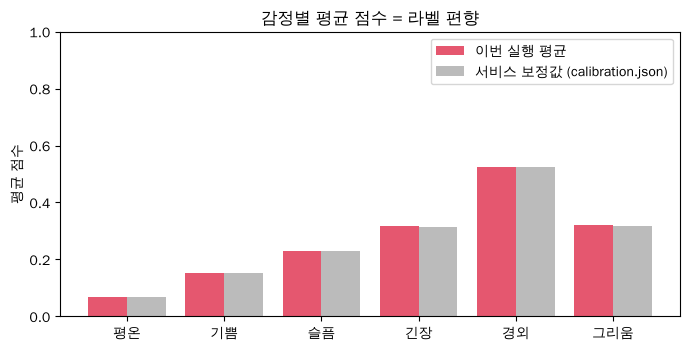

가장 많이 주는 감정: 경외 0.52 / 가장 적게 주는 감정: 평온 0.07


In [5]:
mean_scores = raw_mat.mean(axis=0)
prior_file = load_calibration().get("text", {})

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(EMOTION_KEYS))
ax.bar(x - 0.2, mean_scores, 0.4, label="이번 실행 평균", color="#e5576f")
if prior_file:
    ax.bar(x + 0.2, [prior_file[k] for k in EMOTION_KEYS], 0.4, label="서비스 보정값 (calibration.json)", color="#bbb")
ax.set_xticks(x, KO_LIST); ax.set_ylim(0, 1); ax.set_ylabel("평균 점수")
ax.set_title("감정별 평균 점수 = 라벨 편향")
ax.legend(); fig.tight_layout(); save(fig, "02_label_bias"); plt.show()

print("가장 많이 주는 감정:", KO[EMOTION_KEYS[int(mean_scores.argmax())]], f"{mean_scores.max():.2f}",
      "/ 가장 적게 주는 감정:", KO[EMOTION_KEYS[int(mean_scores.argmin())]], f"{mean_scores.min():.2f}")

## 4. 정확도 — 무작위 기준 · 보정 전후 · 교차검증

**지표**
- **Top-1:** AI의 1위 감정이 정답(1~2개) 안에 있는 비율
- **Top-2:** AI의 1·2위 중 하나라도 정답에 있는 비율

**비교하는 4가지**

| 이름 | 설명 |
|---|---|
| 무작위 기준 | 감정 6개 중 아무거나 골랐을 때 기대 정확도 (이것보다 높아야 의미가 있음) |
| 보정 전 | 모델 원점수 그대로 |
| 보정 (서비스) | 서비스가 실제로 쓰는 방식: `calibration.json`의 감정별 평균을 빼고 0 미만은 0 |
| 보정 (교차검증) | 각 작품을 평가할 때 **그 작품을 뺀 나머지 10점**으로 평균을 구해 보정 (Leave-One-Out) |

> 서비스 보정값은 **이 11점으로 만든 값**이라, 같은 11점으로 평가하면 실제보다 좋게 나올 수 있습니다.
> 교차검증 값이 **처음 보는 작품에서 기대할 수 있는 정확도**에 더 가깝습니다.

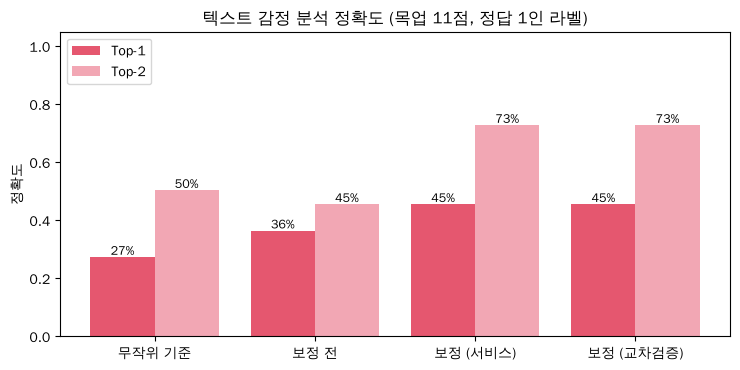

,방식,Top-1,Top-2
0,무작위 기준,27%,50%
1,보정 전,36%,45%
2,보정 (서비스),45%,73%
3,보정 (교차검증),45%,73%


In [6]:
def service_scores(raw_scores, prior):
    # 서비스 analyze()의 텍스트 경로와 동일: 편향 빼기 → 합 1로 정규화 → 최댓값 1로
    return scale_to_max(normalize_sum(apply_prior(raw_scores, prior)))


def rank(final, tiebreak):
    # 점수가 같으면(보정 후 0으로 잘린 감정 등) 원점수로 순위를 정함
    return sorted(EMOTION_KEYS, key=lambda k: (final[k], tiebreak[k]), reverse=True)


def accuracy(rankings):
    top1 = np.mean([rankings[it["id"]][0] in it["expected"] for it in items])
    top2 = np.mean([bool(set(rankings[it["id"]][:2]) & set(it["expected"])) for it in items])
    return top1, top2


# 무작위 기준: 정답 k개일 때 Top-1 = k/6, Top-2 = 1 - C(6-k,2)/C(6,2)
rand_top1 = np.mean([len(it["expected"]) / 6 for it in items])
rand_top2 = np.mean([1 - math.comb(6 - len(it["expected"]), 2) / math.comb(6, 2) for it in items])

rank_raw = {i: rank(raw[i], raw[i]) for i in raw}
final_service = {i: service_scores(raw[i], prior_file) for i in raw}
rank_service = {i: rank(final_service[i], raw[i]) for i in raw}

final_loo = {}
for it in items:
    others = [raw[o["id"]] for o in items if o["id"] != it["id"]]
    prior_loo = {k: float(np.mean([s[k] for s in others])) for k in EMOTION_KEYS}
    final_loo[it["id"]] = service_scores(raw[it["id"]], prior_loo)
rank_loo = {i: rank(final_loo[i], raw[i]) for i in raw}

acc = pd.DataFrame(
    [("무작위 기준", rand_top1, rand_top2), ("보정 전", *accuracy(rank_raw)),
     ("보정 (서비스)", *accuracy(rank_service)), ("보정 (교차검증)", *accuracy(rank_loo))],
    columns=["방식", "Top-1", "Top-2"],
)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(acc))
b1 = ax.bar(x - 0.2, acc["Top-1"], 0.4, label="Top-1", color="#e5576f")
b2 = ax.bar(x + 0.2, acc["Top-2"], 0.4, label="Top-2", color="#f2a7b4")
ax.bar_label(b1, labels=[f"{v:.0%}" for v in acc["Top-1"]], fontsize=9)
ax.bar_label(b2, labels=[f"{v:.0%}" for v in acc["Top-2"]], fontsize=9)
ax.set_xticks(x, acc["방식"]); ax.set_ylim(0, 1.05); ax.set_ylabel("정확도")
ax.set_title(f"텍스트 감정 분석 정확도 (목업 {len(items)}점, 정답 1인 라벨)")
ax.legend(loc="upper left"); fig.tight_layout(); save(fig, "03_accuracy"); plt.show()
acc.style.format({"Top-1": "{:.0%}", "Top-2": "{:.0%}"})

In [7]:
# 작품별 결과: 보정 전/후 1·2위와 정답 비교
rows = []
for it in items:
    i = it["id"]
    mark = lambda r: " ✅" if r[0] in it["expected"] else ""
    rows.append({
        "작품": it["title"], "정답": ", ".join(KO[e] for e in it["expected"]),
        "보정 전 1·2위": f"{KO[rank_raw[i][0]]}, {KO[rank_raw[i][1]]}{mark(rank_raw[i])}",
        "서비스 1·2위": f"{KO[rank_service[i][0]]}, {KO[rank_service[i][1]]}{mark(rank_service[i])}",
        "교차검증 1·2위": f"{KO[rank_loo[i][0]]}, {KO[rank_loo[i][1]]}{mark(rank_loo[i])}",
    })
pd.DataFrame(rows)

,작품,정답,보정 전 1·2위,서비스 1·2위,교차검증 1·2위
0,별이 빛나는 밤,"경외, 긴장","경외, 긴장 ✅","긴장, 그리움 ✅","긴장, 그리움 ✅"
1,수련,평온,"경외, 기쁨","경외, 기쁨","경외, 기쁨"
2,붉은 방 (붉은색의 조화),기쁨,"그리움, 긴장","그리움, 긴장","그리움, 긴장"
3,해바라기,기쁨,"경외, 그리움","경외, 기쁨","경외, 기쁨"
4,"인상, 해돋이","평온, 그리움","경외, 슬픔","슬픔, 평온","슬픔, 평온"
5,구성 VIII,"기쁨, 긴장","평온, 그리움","평온, 그리움","평온, 그리움"
6,절규,"긴장, 슬픔","긴장, 슬픔 ✅","긴장, 슬픔 ✅","긴장, 슬픔 ✅"
7,그랑드자트섬의 일요일 오후,"평온, 기쁨","경외, 기쁨","기쁨, 평온 ✅","기쁨, 평온 ✅"
8,키스,기쁨,"경외, 그리움","경외, 기쁨","경외, 기쁨"
9,진주 귀고리를 한 소녀,"평온, 그리움","그리움, 평온 ✅","평온, 기쁨 ✅","평온, 기쁨 ✅"


## 5. 혼동 행렬 — 어떤 감정을 어떤 감정으로 착각하나

행 = 정답(대표 감정, 첫 번째), 열 = 서비스 방식의 1위 예측. 대각선에 몰릴수록 좋습니다.

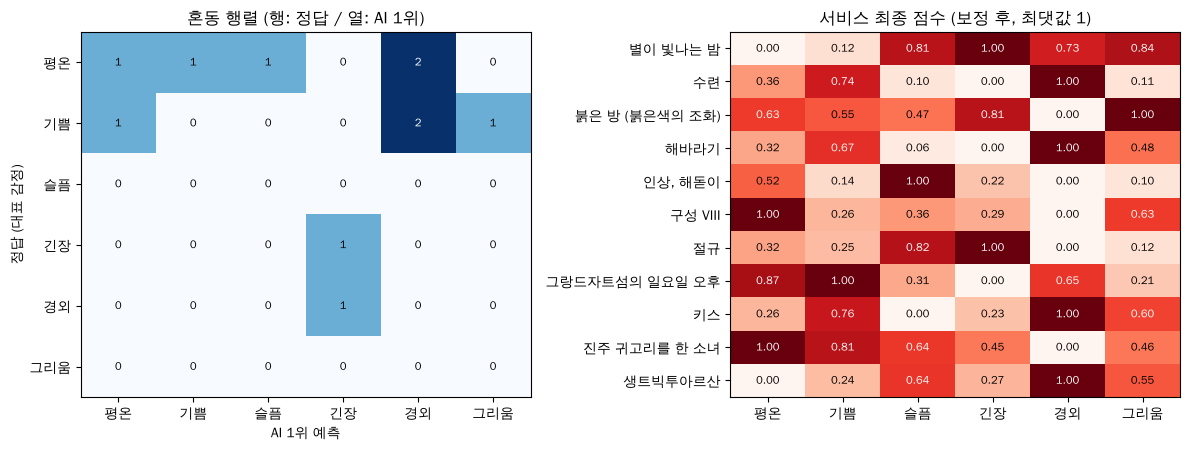

AI가 1위로 고른 감정 분포: {'경외': np.int64(4), '긴장': np.int64(2), '평온': np.int64(2), '그리움': np.int64(1), '슬픔': np.int64(1), '기쁨': np.int64(1)}


In [8]:
conf = np.zeros((6, 6), dtype=int)
for it in items:
    conf[EMOTION_KEYS.index(it["expected"][0]), EMOTION_KEYS.index(rank_service[it["id"]][0])] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
heatmap(axes[0], conf, KO_LIST, KO_LIST, "혼동 행렬 (행: 정답 / 열: AI 1위)", fmt="{:.0f}", cmap="Blues")
axes[0].set_xlabel("AI 1위 예측"); axes[0].set_ylabel("정답 (대표 감정)")

svc_mat = np.array([[final_service[it["id"]][k] for k in EMOTION_KEYS] for it in items])
heatmap(axes[1], svc_mat, titles, KO_LIST, "서비스 최종 점수 (보정 후, 최댓값 1)", vmax=1)
fig.tight_layout(); save(fig, "04_confusion_and_service_scores"); plt.show()

pred_counts = pd.Series([KO[rank_service[i][0]] for i in rank_service]).value_counts()
print("AI가 1위로 고른 감정 분포:", dict(pred_counts))

## 6. 텍스트 모델 비교 (같은 데이터, 모델·설정 4종)

`python -m evaluation.evaluate`로 저장해 둔 결과(`evaluation/results/details.csv`)를 불러와 비교합니다.
`RUN_ALL = True`로 바꾸면 4개 모델을 다시 내려받아 처음부터 실행합니다(CPU로 10~20분).

> 이 표의 「+보정」은 같은 11점 평균을 빼는 방식이라 4장의 「보정 (서비스)」처럼 낙관적인 값입니다.

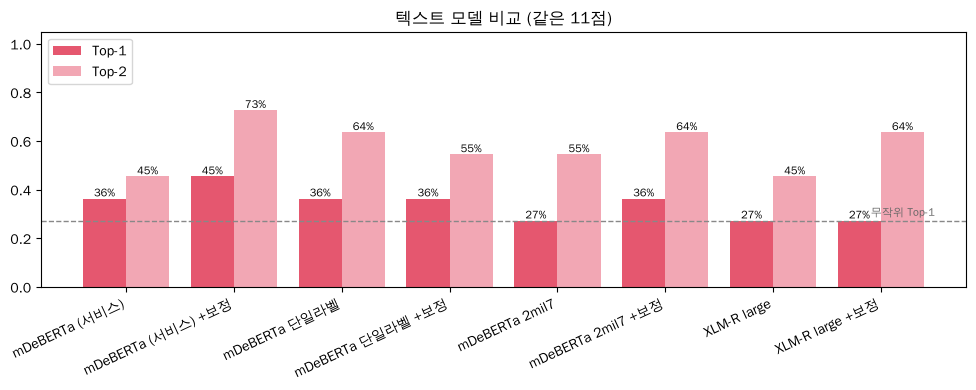

,모델,Top-1,Top-2,작품당 초
0,mDeBERTa (서비스),36%,45%,10.6
1,mDeBERTa (서비스) +보정,45%,73%,10.6
2,mDeBERTa 단일라벨,36%,64%,10.5
3,mDeBERTa 단일라벨 +보정,36%,55%,10.5
4,mDeBERTa 2mil7,27%,55%,12.8
5,mDeBERTa 2mil7 +보정,36%,64%,12.8
6,XLM-R large,27%,45%,2.5
7,XLM-R large +보정,27%,64%,2.5


In [9]:
RUN_ALL = False

if RUN_ALL:
    subprocess.run([sys.executable, "-m", "evaluation.evaluate"], check=True)

details = pd.read_csv("evaluation/results/details.csv", encoding="utf-8-sig")
expected_by_title = {it["title"]: {KO[e] for e in it["expected"]} for it in items}


def cfg_acc(g):
    t1 = np.mean([r["1위"] in expected_by_title[r["작품"]] for _, r in g.iterrows()])
    t2 = np.mean([bool({r["1위"], r["2위"]} & expected_by_title[r["작품"]]) for _, r in g.iterrows()])
    return pd.Series({"Top-1": t1, "Top-2": t2})


cmp = details.groupby("설정", sort=False).apply(cfg_acc).reset_index()

# 작품당 처리 시간은 report.md 표에서 읽음
times = {}
for line in Path("evaluation/results/report.md").read_text(encoding="utf-8").splitlines():
    m = re.match(r"\|\s*([^|]+?)\s*\|.*\|\s*([\d.]+)초\s*\|$", line)
    if m:
        times[m.group(1)] = float(m.group(2))
cmp["작품당 초"] = cmp["설정"].map(times)

NAMES = {"current": "mDeBERTa (서비스)", "single": "mDeBERTa 단일라벨", "2mil7": "mDeBERTa 2mil7", "large": "XLM-R large"}
cmp["모델"] = cmp["설정"].map(lambda s: NAMES.get(s.replace("+보정", ""), s) + (" +보정" if "+보정" in s else ""))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cmp))
b1 = ax.bar(x - 0.2, cmp["Top-1"], 0.4, label="Top-1", color="#e5576f")
b2 = ax.bar(x + 0.2, cmp["Top-2"], 0.4, label="Top-2", color="#f2a7b4")
ax.bar_label(b1, labels=[f"{v:.0%}" for v in cmp["Top-1"]], fontsize=8)
ax.bar_label(b2, labels=[f"{v:.0%}" for v in cmp["Top-2"]], fontsize=8)
ax.axhline(rand_top1, color="#888", ls="--", lw=1); ax.text(len(cmp) - 0.5, rand_top1 + 0.02, "무작위 Top-1", color="#666", fontsize=8, ha="right")
ax.set_xticks(x, cmp["모델"], rotation=25, ha="right"); ax.set_ylim(0, 1.05)
ax.set_title("텍스트 모델 비교 (같은 11점)"); ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "05_model_comparison"); plt.show()
cmp[["모델", "Top-1", "Top-2", "작품당 초"]].style.format({"Top-1": "{:.0%}", "Top-2": "{:.0%}", "작품당 초": "{:.1f}"})

## 7. 이미지 분석(CLIP) — 그림을 보고 감정을 그럴듯하게 고르나 (정성 확인)

공개 미술 데이터셋 [WikiArt (huggan/wikiart)](https://huggingface.co/datasets/huggan/wikiart)에서 화가·장르가 다른 9점을 골라 CLIP으로 분석합니다.
서비스의 `HuggingFaceScorer.image_scores`와 같은 코드입니다.

> ⚠️ 이 9점에는 **정답 라벨이 없습니다.** "사람이 봐도 그럴듯한가"를 눈으로 확인하는 **정성 평가**이고, 정확도 수치가 아닙니다.
> 이미지 정확도를 재려면 실제 전시 작품 캡처에 팀 라벨을 붙여 `python -m evaluation.evaluate --image`를 실행하세요.

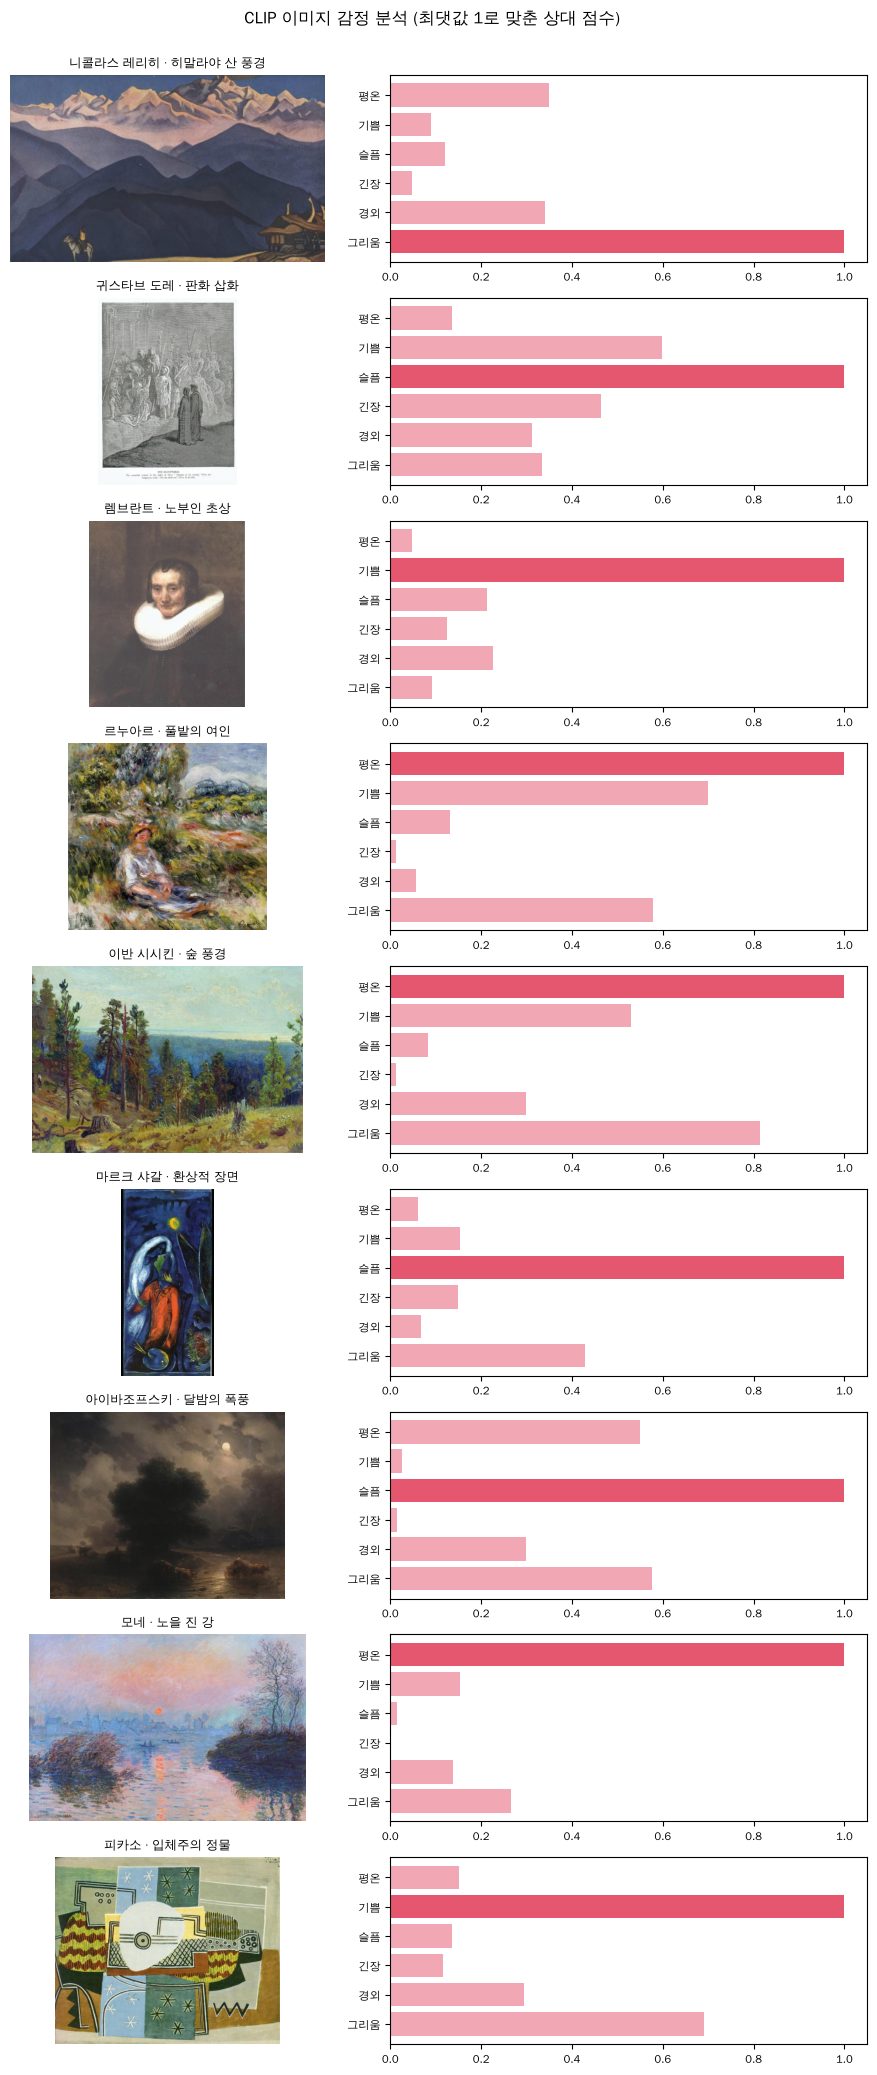

,그림,1위,2위
0,니콜라스 레리히 · 히말라야 산 풍경,그리움,평온
1,귀스타브 도레 · 판화 삽화,슬픔,기쁨
2,렘브란트 · 노부인 초상,기쁨,경외
3,르누아르 · 풀밭의 여인,평온,기쁨
4,이반 시시킨 · 숲 풍경,평온,그리움
5,마르크 샤갈 · 환상적 장면,슬픔,그리움
6,아이바조프스키 · 달밤의 폭풍,슬픔,그리움
7,모네 · 노을 진 강,평온,그리움
8,피카소 · 입체주의 정물,기쁨,그리움


In [10]:
WIKIART = [  # (데이터셋 행 번호, 설명)
    (12, "니콜라스 레리히 · 히말라야 산 풍경"), (17, "귀스타브 도레 · 판화 삽화"), (24, "렘브란트 · 노부인 초상"),
    (3, "르누아르 · 풀밭의 여인"), (6026, "이반 시시킨 · 숲 풍경"), (68, "마르크 샤갈 · 환상적 장면"),
    (7, "아이바조프스키 · 달밤의 폭풍"), (71, "모네 · 노을 진 강"), (99, "피카소 · 입체주의 정물"),
]
IMG_DIR = Path("evaluation/images")  # Git에 올라가지 않는 폴더
IMG_DIR.mkdir(exist_ok=True)
ROWS_API = "https://datasets-server.huggingface.co/rows?dataset=huggan/wikiart&config=default&split=train&offset={}&length=1"


def wikiart_image(idx):
    path = IMG_DIR / f"wikiart_{idx}.jpg"
    if not path.exists():
        row = json.load(urllib.request.urlopen(ROWS_API.format(idx), timeout=60))["rows"][0]["row"]
        path.write_bytes(urllib.request.urlopen(row["image"]["src"], timeout=60).read())
    return Image.open(path).convert("RGB")


gallery = []
for idx, label in WIKIART:
    img = wikiart_image(idx)
    img.thumbnail((512, 512))  # CLIP은 224×224로 줄여서 보므로 결과는 같고, 그래프 용량만 줄어듦
    scores = scale_to_max(normalize_sum(scorer.image_scores(img)))
    gallery.append((label, img, scores))

fig, axes = plt.subplots(len(gallery), 2, figsize=(9, 2.3 * len(gallery)), gridspec_kw={"width_ratios": [1, 1.4]})
for r, (label, img, scores) in enumerate(gallery):
    axes[r][0].imshow(img); axes[r][0].axis("off"); axes[r][0].set_title(label, fontsize=9)
    vals = [scores[k] for k in EMOTION_KEYS]
    colors = ["#e5576f" if v == max(vals) else "#f2a7b4" for v in vals]
    axes[r][1].barh(KO_LIST[::-1], vals[::-1], color=colors[::-1]); axes[r][1].set_xlim(0, 1.05)
    axes[r][1].tick_params(labelsize=8)
fig.suptitle("CLIP 이미지 감정 분석 (최댓값 1로 맞춘 상대 점수)", y=1.0)
fig.tight_layout(); save(fig, "06_clip_gallery", dpi=80); plt.show()

pd.DataFrame([{"그림": l, "1위": KO[max(s, key=s.get)], "2위": KO[sorted(s, key=s.get)[-2]]} for l, _, s in gallery])

## 8. 이미지 + 텍스트를 합치면 — 「인상, 해돋이」 해설 + 모네의 노을 그림

서비스는 이미지 60% + 텍스트 40%로 합칩니다(`config.IMAGE_WEIGHT`).
목업 작품 「인상, 해돋이」(정답: 평온·그리움)의 **해설**과, 7장의 **모네 노을 그림**(같은 화가·비슷한 주제의 대체 이미지)으로 세 가지를 비교합니다.

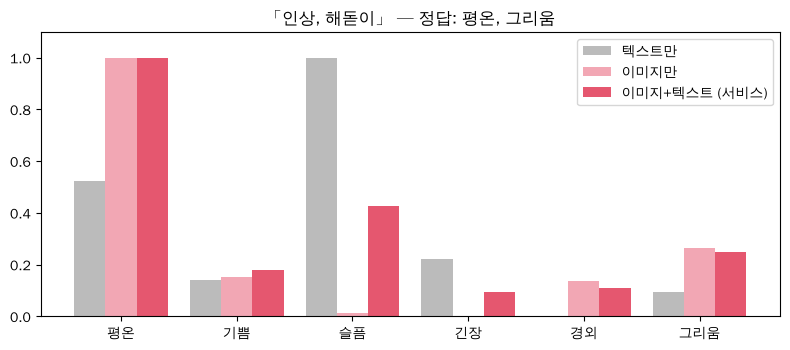

텍스트만       1·2위: 슬픔, 평온
이미지만       1·2위: 평온, 그리움
이미지+텍스트    1·2위: 평온, 슬픔


In [11]:
it5 = next(it for it in items if it["id"] == "aw-05")
txt5 = final_service["aw-05"]
img5 = next(s for l, _, s in gallery if l.startswith("모네"))
both5 = combine(img5, txt5, config.IMAGE_WEIGHT)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(6)
for off, (name, s, c) in zip([-0.27, 0, 0.27], [("텍스트만", txt5, "#bbb"), ("이미지만", img5, "#f2a7b4"), ("이미지+텍스트 (서비스)", both5, "#e5576f")]):
    ax.bar(x + off, [s[k] for k in EMOTION_KEYS], 0.27, label=name, color=c)
ax.set_xticks(x, KO_LIST); ax.set_ylim(0, 1.1)
ax.set_title(f"「{it5['title']}」 — 정답: " + ", ".join(KO[e] for e in it5["expected"]))
ax.legend(); fig.tight_layout(); save(fig, "07_image_text_combined"); plt.show()

for name, s in [("텍스트만", txt5), ("이미지만", img5), ("이미지+텍스트", both5)]:
    top = sorted(EMOTION_KEYS, key=s.get, reverse=True)[:2]
    print(f"{name:10s} 1·2위: {KO[top[0]]}, {KO[top[1]]}")

## 9. 추천과의 연결 — 사용자 취향과 작품 감정을 어떻게 잇나

사용자가 고른 **취향 카드** → 미리 정한 변환표(`backend/src/lib/emotion.ts`의 `TASTE_EMOTIONS`)로 **감정 6칸 점수** → 작품의 AI 감정 점수와 **코사인 유사도** 계산.
실제 추천 점수는 `0.7 × 감정 유사도 + 0.3 × 취향 태그 일치율`이며, 여기서는 감정 유사도 부분만 봅니다.

> ⚠️ 변환표 숫자와 0.7/0.3 비율은 **데이터로 정한 값이 아니라 설계 가정**입니다. 설문 등으로 근거를 만들 대상입니다.

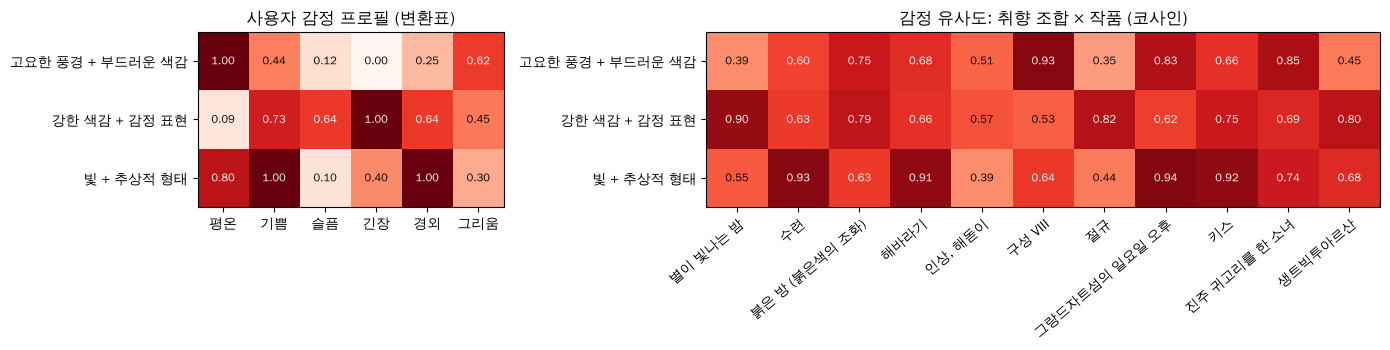

고요한 풍경 + 부드러운 색감 → 감정이 가장 닮은 작품: 구성 VIII(0.93), 진주 귀고리를 한 소녀(0.85), 그랑드자트섬의 일요일 오후(0.83)
강한 색감 + 감정 표현  → 감정이 가장 닮은 작품: 별이 빛나는 밤(0.90), 절규(0.82), 생트빅투아르산(0.80)
빛 + 추상적 형태     → 감정이 가장 닮은 작품: 그랑드자트섬의 일요일 오후(0.94), 수련(0.93), 키스(0.92)


In [12]:
# backend/src/lib/emotion.ts 의 TASTE_EMOTIONS 와 같은 값 (바꾸면 양쪽을 함께 수정)
TASTE_EMOTIONS = {
    "강한 색감": dict(calm=0.1, joy=0.6, sadness=0.1, tension=0.5, awe=0.4, nostalgia=0.1),
    "고요한 풍경": dict(calm=0.9, joy=0.2, sadness=0.1, tension=0.0, awe=0.3, nostalgia=0.5),
    "추상적 형태": dict(calm=0.3, joy=0.3, sadness=0.1, tension=0.4, awe=0.5, nostalgia=0.1),
    "부드러운 색감": dict(calm=0.7, joy=0.5, sadness=0.1, tension=0.0, awe=0.1, nostalgia=0.5),
    "감정 표현": dict(calm=0.0, joy=0.2, sadness=0.6, tension=0.6, awe=0.3, nostalgia=0.4),
    "빛": dict(calm=0.5, joy=0.7, sadness=0.0, tension=0.0, awe=0.5, nostalgia=0.2),
}


def profile(cards):
    # 고른 카드 평균 → 가장 큰 값을 1로
    s = {k: np.mean([TASTE_EMOTIONS[c][k] for c in cards]) for k in EMOTION_KEYS}
    top = max(s.values())
    return {k: v / top for k, v in s.items()}


def cosine(a, b):
    va, vb = np.array([a[k] for k in EMOTION_KEYS]), np.array([b[k] for k in EMOTION_KEYS])
    return float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb) + 1e-12))


COMBOS = [("고요한 풍경", "부드러운 색감"), ("강한 색감", "감정 표현"), ("빛", "추상적 형태")]
profiles = {" + ".join(c): profile(c) for c in COMBOS}
sim = np.array([[cosine(p, final_service[it["id"]]) for it in items] for p in profiles.values()])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
heatmap(axes[0], np.array([[p[k] for k in EMOTION_KEYS] for p in profiles.values()]), list(profiles), KO_LIST, "사용자 감정 프로필 (변환표)", vmax=1)
heatmap(axes[1], sim, list(profiles), titles, "감정 유사도: 취향 조합 × 작품 (코사인)", vmax=1)
plt.setp(axes[1].get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
fig.tight_layout(); save(fig, "08_taste_artwork_similarity"); plt.show()

for name, row in zip(profiles, sim):
    best = np.argsort(row)[::-1][:3]
    print(f"{name:14s} → 감정이 가장 닮은 작품: " + ", ".join(f"{titles[j]}({row[j]:.2f})" for j in best))

## 10. 팀 라벨 일치도 — 정답의 근거 만들기

정답을 1명이 정하면 그 사람의 감각이 기준이 됩니다. 팀원 여러 명이 **각자** 라벨을 달고 비교하면,
① 사람끼리 얼마나 일치하는지(**과제 자체의 난이도**), ② 다수결 정답으로 본 AI 정확도를 함께 얻을 수 있습니다.

**방법:** `evaluation/team_labels.csv`를 만들고 아래 형식으로 채운 뒤 이 셀을 다시 실행하세요.

```csv
id,평가자,감정1,감정2
aw-01,김광권,경외,긴장
aw-01,임준억,긴장,
aw-02,김광권,평온,
...
```

In [13]:
LABEL_FILE = Path("evaluation/team_labels.csv")
KO2KEY = {v: k for k, v in KO.items()}

if not LABEL_FILE.exists():
    print(f"{LABEL_FILE} 이 아직 없습니다. 팀원 2명 이상의 라벨을 모으면 일치도와 다수결 정확도를 계산합니다.")
else:
    lab = pd.read_csv(LABEL_FILE, encoding="utf-8-sig").fillna("")
    raters = sorted(lab["평가자"].unique())
    sets = {(r.id, r.평가자): {KO2KEY[e] for e in (r.감정1, r.감정2) if e} for r in lab.itertuples()}
    ids = [it["id"] for it in items if all((it["id"], p) in sets for p in raters)]
    print(f"평가자 {len(raters)}명 · 공통 작품 {len(ids)}점")

    # (1) 평가자 쌍별 일치도: 대표 감정(감정1) 일치율, 감정 집합이 하나라도 겹치는 비율
    pair_rows = []
    for a, b in combinations(raters, 2):
        first = np.mean([lab[(lab.id == i) & (lab.평가자 == a)].감정1.iat[0] == lab[(lab.id == i) & (lab.평가자 == b)].감정1.iat[0] for i in ids])
        overlap = np.mean([bool(sets[(i, a)] & sets[(i, b)]) for i in ids])
        pair_rows.append({"평가자 쌍": f"{a} – {b}", "대표 감정 일치": first, "하나라도 겹침": overlap})
    display(pd.DataFrame(pair_rows).style.format({"대표 감정 일치": "{:.0%}", "하나라도 겹침": "{:.0%}"}))

    # (2) Fleiss' kappa (대표 감정 기준, 우연히 일치할 확률을 뺀 일치도: 0.2↓ 약함, 0.4~0.6 보통, 0.6↑ 상당)
    n = len(raters)
    counts = np.array([[sum(lab[(lab.id == i) & (lab.평가자 == p)].감정1.iat[0] == KO[k] for p in raters) for k in EMOTION_KEYS] for i in ids])
    p_i = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    p_j = counts.sum(axis=0) / counts.sum()
    kappa = (p_i.mean() - (p_j ** 2).sum()) / (1 - (p_j ** 2).sum())
    print(f"Fleiss' kappa = {kappa:.2f}")

    # (3) 다수결 정답(2명 이상이 고른 감정, 없으면 최다 득표)으로 AI 정확도 다시 계산
    majority = {}
    for i in ids:
        votes = pd.Series([e for p in raters for e in sets[(i, p)]]).value_counts()
        majority[i] = set(votes[votes >= 2].index) or {votes.index[0]}
    t1 = np.mean([rank_loo[i][0] in majority[i] for i in ids])
    t2 = np.mean([bool(set(rank_loo[i][:2]) & majority[i]) for i in ids])
    print(f"다수결 정답 기준 AI 정확도 (교차검증 보정): Top-1 {t1:.0%}, Top-2 {t2:.0%}")

evaluation/team_labels.csv 이 아직 없습니다. 팀원 2명 이상의 라벨을 모으면 일치도와 다수결 정확도를 계산합니다.


## 11. 결론

### 숫자 요약 (이번 실행)

In [14]:
summary = {
    "평가 작품 수": len(items),
    "작품당 텍스트 분석 시간(초, CPU)": round(sec_per_item, 1),
    **{f"{r['방식']} Top-1": f"{r['Top-1']:.0%}" for _, r in acc.iterrows()},
    **{f"{r['방식']} Top-2": f"{r['Top-2']:.0%}" for _, r in acc.iterrows()},
}
pd.Series(summary, name="값").to_frame()

,값
평가 작품 수,11
"작품당 텍스트 분석 시간(초, CPU)",0.9
무작위 기준 Top-1,27%
보정 전 Top-1,36%
보정 (서비스) Top-1,45%
보정 (교차검증) Top-1,45%
무작위 기준 Top-2,50%
보정 전 Top-2,45%
보정 (서비스) Top-2,73%
보정 (교차검증) Top-2,73%


### 해석 (2026-10-24 실행 결과를 보고 작성 — 데이터를 바꿔 다시 실행했다면 함께 고쳐 주세요)

**1. 텍스트 분석은 무작위보다는 낫지만 "대략적인 경향" 수준이다**
- 보정 후 **Top-1 45% / Top-2 73%** (무작위 기준 27% / 50%, 보정 전 36% / 45%).
- 각 작품을 빼고 보정값을 만든 **교차검증에서도 같은 값** → 보정이 이 11점에만 맞춘 결과는 아니다.
- 단, **작품 11점·정답 1인 라벨**이라 한 작품만 바뀌어도 정확도가 9%p씩 움직인다.

**2. 가장 큰 문제는 라벨 편향 — '경외'에 쏠린다**
- 감정별 평균 점수: 경외 0.52, 평온 0.07 (약 7배). 보정 후에도 11점 중 4점의 1위가 경외(수련·해바라기·키스·생트빅투아르산).
- 혼동 행렬에서 **정답이 '기쁨'인 4점은 하나도 1위로 맞히지 못했다**(평온·경외·그리움으로 착각). 기쁨 인식이 특히 약하다.
- 칸딘스키 「구성 VIII」을 '평온'으로 판단하는 등 해설 문장의 단어에 끌려가는 오류가 있다.

**3. 이미지 분석(CLIP)은 풍경·밝은 그림에서 자연스럽고, 어둡거나 초상인 그림에서 어색하다 (정성 확인, 개발자 판단)**
- 자연스러움: 레리히 산 풍경(그리움·평온), 르누아르(평온·기쁨), 시시킨 숲(평온), 모네 노을(평온·그리움), 피카소 정물(기쁨)
- 어색함: 렘브란트 노부인 초상 → 기쁨, 아이바조프스키 달밤 폭풍 → 슬픔(긴장·경외를 기대), 샤갈 → 슬픔(파란 색조 영향으로 추정), 흑백 판화 → 슬픔
- 정답 라벨이 없는 9점이므로 정확도로 말할 수 없다.

**4. 이미지와 텍스트를 합치면 서로의 오류를 보완할 수 있다 (사례 1건)**
- 「인상, 해돋이」: 텍스트만 → 1위 슬픔(오답) / 이미지 결합 → 1위 **평온(정답)**, 그리움도 올라감.

**5. AI 오류는 추천으로 그대로 전파된다 → 관리자 확정 단계가 필요한 이유**
- 「구성 VIII」이 '평온'으로 잘못 분석되어, '고요한 풍경 + 부드러운 색감' 사용자에게 **감정이 가장 닮은 작품 1위(0.93)**로 나온다.
- 그래서 ARTI는 AI 결과를 「AI 제안」으로만 저장하고, 관리자가 확인·수정한 뒤 「확정」해야 추천에 쓴다.

**6. 검증 중 발견해 고친 문제**
- 예전 보정은 모든 감정이 평균보다 낮으면 **보정 전 점수로 돌아가** 편향이 그대로 남았다(그랑드자트섬·진주 귀고리 소녀).
  편향을 뺀 순서를 끝까지 유지하도록 `apply_prior`를 고쳤고, 서비스 방식의 정확도가 36% / 64% → **45% / 73%**가 되었다.

### 한계와 다음 단계
| 한계 | 다음 단계 |
|---|---|
| 정답을 1명이 정함 | 팀원 각자 라벨 → `team_labels.csv` → 10장 실행 (일치도·다수결 정확도) |
| 목업 11점, 유명 서양화 | 실제 전시(유영국) 작품 20~30점 + 캡처 이미지로 `python -m evaluation.evaluate --image` |
| 이미지 정확도 미측정 | 위 데이터로 이미지·텍스트·결합 정확도 비교 |
| 파인튜닝 없음(제로샷) | 라벨이 모이면 CLIP 리니어 프로브(CPU 가능) 또는 ArtEmis로 파인튜닝(GPU) |
| 취향→감정 변환표·0.7/0.3 비율이 설계 가정 | 사용자 설문으로 변환표 보정, 👍/👎 반응으로 비율 검증 |